In [10]:
import os
import h5py
import requests
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive,userdata
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
os.chdir("/content/drive/MyDrive/TNGdata")

In [12]:
baseUrl = 'http://www.tng-project.org/api/'
headers = {"api-key":userdata.get("TNG_API_KEY")}

In [13]:
def get(path, params=None):
    # make HTTP GET request to path
    r = requests.get(path, params=params, headers=headers)

    # raise exception if response code is not HTTP SUCCESS (200)
    r.raise_for_status()

    if r.headers['content-type'] == 'application/json':
        return r.json() # parse json responses automatically

    if 'content-disposition' in r.headers:
        filename = r.headers['content-disposition'].split("filename=")[1]
        with open(filename, 'wb') as f:
            f.write(r.content)
        return filename # return the filename string

    return r

In [14]:
r = get(baseUrl)

In [15]:
data = np.load("subhalo_data_with_bhmasses.npz")
data = data["data"]

sfrs = data[:,0,0]
bhmdots = data[:,0,1]
mass_stars = data[:,0,2]
mass_bhmdots = data[:,0,3]
mass_log_msun = data[:,0,4]

normalized_sfrs = sfrs / mass_stars
normalized_bhmdots = bhmdots / mass_bhmdots

/tmp/ipykernel_5026/1313167293.py:11: RuntimeWarning: invalid value encountered in divide
  normalized_bhmdots = bhmdots / mass_bhmdots


In [17]:
valid_mask = (sfrs >= 0) & (bhmdots >= 0) & (mass_stars > 0) & (mass_bhmdots > 0)

clean_norm_sfrs = normalized_sfrs[valid_mask]
clean_norm_bhmdots = normalized_bhmdots[valid_mask]
clean_mstar = mass_stars[valid_mask]
clean_mbh = mass_bhmdots[valid_mask]

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_5026/1918445994.py:6: SyntaxWarning: invalid escape sequence '\d'
  plt.ylabel('Normalized $\dot{M}_{BH}$ [$yr^{-1}$]')


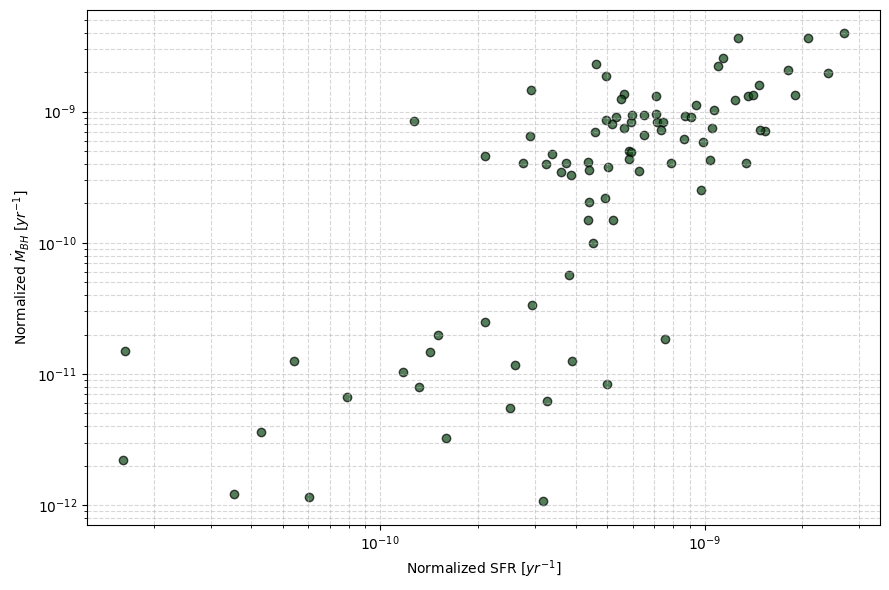

In [21]:
plt.figure(figsize=(9, 6))
plt.scatter(clean_norm_sfrs, clean_norm_bhmdots, color='#0b4714', alpha=0.7, edgecolors='k')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Normalized SFR [$yr^{-1}$]')
plt.ylabel('Normalized $\dot{M}_{BH}$ [$yr^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("normalized_sfr_vs_bhmdot_scatter.png", dpi=300)
plt.show()

<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_5026/3102602323.py:5: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Stellar Mass [$\mathrm{M}_{\odot}$]')
/tmp/ipykernel_5026/3102602323.py:6: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Black Hole Mass [$\mathrm{M}_{\odot}$]')


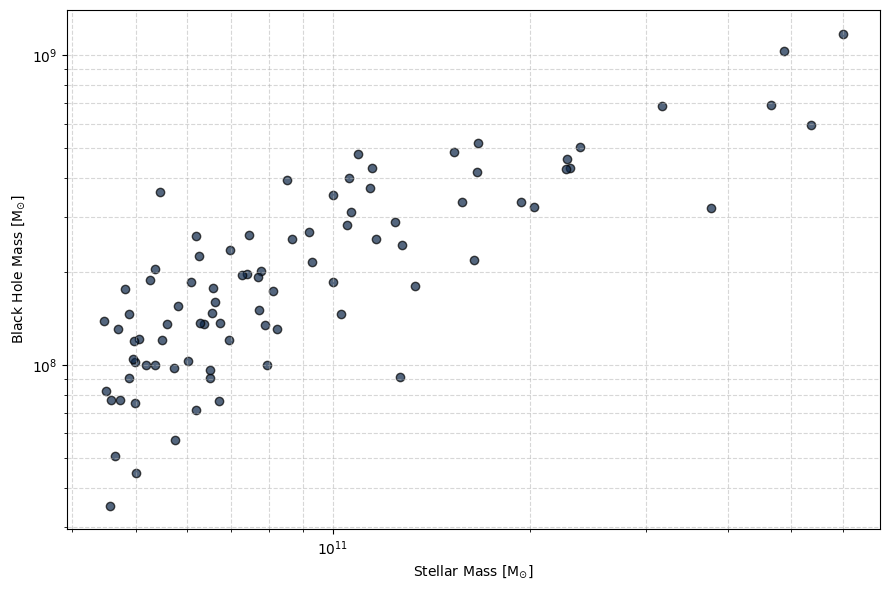

In [22]:
plt.figure(figsize=(9, 6))
plt.scatter(clean_mstar, clean_mbh, color='#0b2547', alpha=0.7, edgecolors='k')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Stellar Mass [$\mathrm{M}_{\odot}$]')
plt.ylabel('Black Hole Mass [$\mathrm{M}_{\odot}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("mstar_vs_mbh_scatter.png", dpi=300)
plt.show()